# Model 3: SVM vs Decision Tree Comparison

**Research Question:** Can we predict whether an employee believes discussing mental health with their employer would have negative consequences?

**Target:** `mental_health_consequence`

**Features:** Workplace perception columns — supervisor, coworkers, anonymity, obs_consequence, mental_vs_physical, benefits, seek_help, wellness_program, work_interfere, no_employees, remote_work, tech_company

In [1]:
import pandas as pd
import numpy as np
import sys
import os
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Add src directory to path and import utils
sys.path.append(os.path.abspath('../src'))
from utils import save_figure, plot_confusion_matrix

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

# Load and reset
df = pd.read_csv('../data/cleaned_survey.csv')
df = df.reset_index(drop=True)

# Reconstruct target from one-hot encoded columns
# mental_health_consequence_Yes = True means "Yes", False means "No"
# Rows where both are False = originally "Maybe" — label as 2
conditions = [
    df['mental_health_consequence_Yes'] == True,
    df['mental_health_consequence_No'] == True
]
choices = [1, 0]
y = pd.Series(
    np.select(conditions, choices, default=2),
    name='mental_health_consequence'
)

print("Reconstructed target distribution:")
print(y.value_counts())
print("0 = No, 1 = Yes, 2 = Maybe")

# Drop the original one-hot target columns from features
drop_cols = ['mental_health_consequence_No', 'mental_health_consequence_Yes']
X = df.drop(columns=drop_cols).copy()

# Drop target one-hot columns to prevent data leakage
leakage_cols = [col for col in X.columns if 'mental_health_consequence' in col or 'phys_health_consequence' in col]
print("Dropping leakage columns:", leakage_cols)
X = X.drop(columns=leakage_cols)
print("X shape after dropping leakage columns:", X.shape)

# Fill any remaining NaNs in X
for col in X.columns:
    if X[col].isna().sum() > 0:
        if X[col].dtype == 'object':
            X[col] = X[col].fillna(X[col].mode()[0] if not X[col].mode().empty else 'Unknown')
        else:
            X[col] = X[col].fillna(X[col].median())

# Convert any boolean columns to int
bool_cols = X.select_dtypes(include='bool').columns.tolist()
X[bool_cols] = X[bool_cols].astype(int)

# Final verification
print("\nX shape:", X.shape)
print("y shape:", y.shape)
print("NaNs in X:", X.isna().sum().sum())
print("NaNs in y:", y.isna().sum())

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTraining set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

Reconstructed target distribution:
mental_health_consequence
0    487
2    476
1    288
Name: count, dtype: int64
0 = No, 1 = Yes, 2 = Maybe
Dropping leakage columns: ['phys_health_consequence_No', 'phys_health_consequence_Yes']
X shape after dropping leakage columns: (1251, 74)

X shape: (1251, 74)
y shape: (1251,)
NaNs in X: 0
NaNs in y: 0

Training set shape: (1000, 74)
Test set shape: (251, 74)


Training set shape: (1000, 74)
Test set shape: (251, 74)

Training target distribution:
mental_health_consequence
0    38.9
2    38.1
1    23.0
Name: proportion, dtype: float64


## SVM Model

In [3]:
# Remove SMOTE — use class_weight='balanced' instead to handle imbalance
# Do NOT apply SMOTE for SVM

# Feature selection — drop sparse country columns before SVM training
country_cols = [col for col in X_train.columns if col.startswith('Country_')]
X_train_svm = X_train.drop(columns=country_cols)
X_test_svm = X_test.drop(columns=country_cols)
print(f"SVM feature count after dropping country dummies: {X_train_svm.shape[1]}")

# Scale features (critical for SVM)
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_svm_scaled = scaler.fit_transform(X_train_svm)
X_test_svm_scaled = scaler.transform(X_test_svm)

# Train SVM with class_weight balanced, no SMOTE
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

param_grid_svm = {
    'C': [0.1, 1, 10],
    'gamma': ['scale', 'auto'],
    'kernel': ['rbf', 'linear']
}

svm_grid = GridSearchCV(
    SVC(class_weight='balanced', random_state=42, probability=True),
    param_grid_svm,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1
)
svm_grid.fit(X_train_svm_scaled, y_train)

print("Best SVM parameters:", svm_grid.best_params_)
print("Best CV F1:", svm_grid.best_score_)

# Evaluate
y_pred_svm = svm_grid.predict(X_test_svm_scaled)

# Overfitting check
train_acc_svm = svm_grid.score(X_train_svm_scaled, y_train)
test_acc_svm = svm_grid.score(X_test_svm_scaled, y_test)
print(f"SVM Train accuracy: {train_acc_svm:.4f}")
print(f"SVM Test accuracy:  {test_acc_svm:.4f}")
print(f"SVM Gap: {train_acc_svm - test_acc_svm:.4f}  (should be < 0.10)")

SVM feature count after dropping country dummies: 29
Best SVM parameters: {'C': 0.1, 'gamma': 'auto', 'kernel': 'rbf'}
Best CV F1: 0.6235406891262247
SVM Train accuracy: 0.6765
SVM Test accuracy:  0.6416
SVM Gap: 0.0349  (should be < 0.10)


In [4]:
# Get best SVM model
best_svm = svm_grid.best_estimator_

# Calculate SVM metrics
svm_accuracy = accuracy_score(y_test, y_pred_svm)
svm_precision = precision_score(y_test, y_pred_svm, average='macro')
svm_recall = recall_score(y_test, y_pred_svm, average='macro')
svm_f1 = f1_score(y_test, y_pred_svm, average='macro')

print("="*60)
print("SVM - Performance Metrics")
print("="*60)
print(f"Accuracy:  {svm_accuracy:.4f}")
print(f"Precision: {svm_precision:.4f}")
print(f"Recall:    {svm_recall:.4f}")
print(f"F1 Score:  {svm_f1:.4f}")
print("="*60)

SVM - Performance Metrics
Accuracy:  0.6414
Precision: 0.6420
Recall:    0.6402
F1 Score:  0.6411


Saved figure to ../outputs/figures\svm_confusion_matrix.png


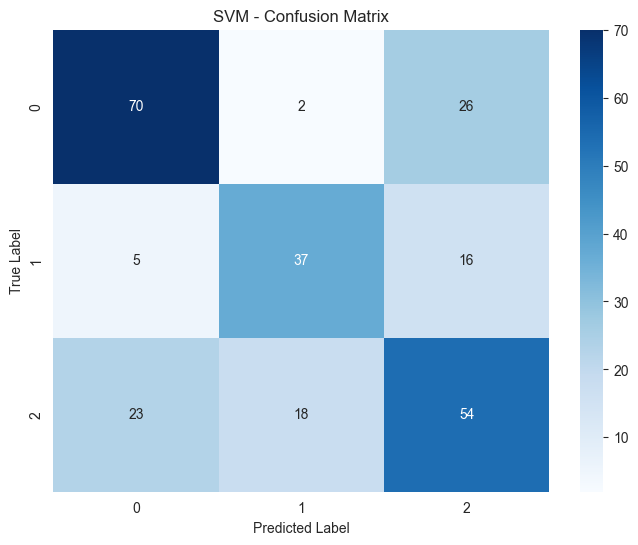


SVM Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.71      0.71        98
           1       0.65      0.64      0.64        58
           2       0.56      0.57      0.57        95

    accuracy                           0.64       251
   macro avg       0.64      0.64      0.64       251
weighted avg       0.64      0.64      0.64       251



In [5]:
# SVM Confusion Matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)
class_names = sorted(y_test.unique())

fig = plot_confusion_matrix(cm_svm, class_names, 'SVM - Confusion Matrix')
save_figure(fig, 'svm_confusion_matrix', output_dir='../outputs/figures')
plt.show()

print("\nSVM Classification Report:")
print(classification_report(y_test, y_pred_svm, target_names=[str(c) for c in class_names]))

## Decision Tree Model

In [6]:
# Use the same reduced feature set for Decision Tree (fair comparison)
X_train_dt = X_train.drop(columns=country_cols)
X_test_dt = X_test.drop(columns=country_cols)
print(f"Decision Tree feature count after dropping country dummies: {X_train_dt.shape[1]}")

# Define Decision Tree parameter grid with constraints to prevent overfitting
dt_param_grid = {
    'max_depth': [3, 4, 5, 6],
    'min_samples_split': [10, 20, 30],
    'min_samples_leaf': [5, 10, 15],
    'class_weight': ['balanced']
}

# Create GridSearchCV for Decision Tree
dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    dt_param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

# Fit Decision Tree grid search
print("Training Decision Tree with GridSearchCV...")
dt_grid.fit(X_train_dt, y_train)

print(f"\nBest Decision Tree parameters: {dt_grid.best_params_}")
print(f"Best cross-validation F1 score: {dt_grid.best_score_:.4f}")

Decision Tree feature count after dropping country dummies: 29
Training Decision Tree with GridSearchCV...
Fitting 5 folds for each of 36 candidates, totalling 180 fits

Best Decision Tree parameters: {'class_weight': 'balanced', 'max_depth': 4, 'min_samples_leaf': 10, 'min_samples_split': 30}
Best cross-validation F1 score: 0.5997


In [7]:
# Get best Decision Tree model
best_dt = dt_grid.best_estimator_

# Overfitting check
print("Decision Tree best params:", dt_grid.best_params_)
print(f"Train accuracy: {dt_grid.score(X_train_dt, y_train):.4f}")
print(f"Test accuracy:  {dt_grid.score(X_test_dt, y_test):.4f}")
gap = dt_grid.score(X_train_dt, y_train) - dt_grid.score(X_test_dt, y_test)
print(f"Overfitting gap: {gap:.4f}  (should be < 0.05)")

# Make predictions
y_pred_dt = best_dt.predict(X_test_dt)

# Calculate Decision Tree metrics
dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt, average='macro')
dt_recall = recall_score(y_test, y_pred_dt, average='macro')
dt_f1 = f1_score(y_test, y_pred_dt, average='macro')

print("="*60)
print("Decision Tree - Performance Metrics")
print("="*60)
print(f"Accuracy:  {dt_accuracy:.4f}")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall:    {dt_recall:.4f}")
print(f"F1 Score:  {dt_f1:.4f}")
print("="*60)

Decision Tree best params: {'class_weight': 'balanced', 'max_depth': 4, 'min_samples_leaf': 10, 'min_samples_split': 30}
Train accuracy: 0.6430
Test accuracy:  0.5962
Overfitting gap: 0.0468  (should be < 0.05)
Decision Tree - Performance Metrics
Accuracy:  0.5896
Precision: 0.5956
Recall:    0.5977
F1 Score:  0.5962


Saved figure to ../outputs/figures\dt_confusion_matrix.png


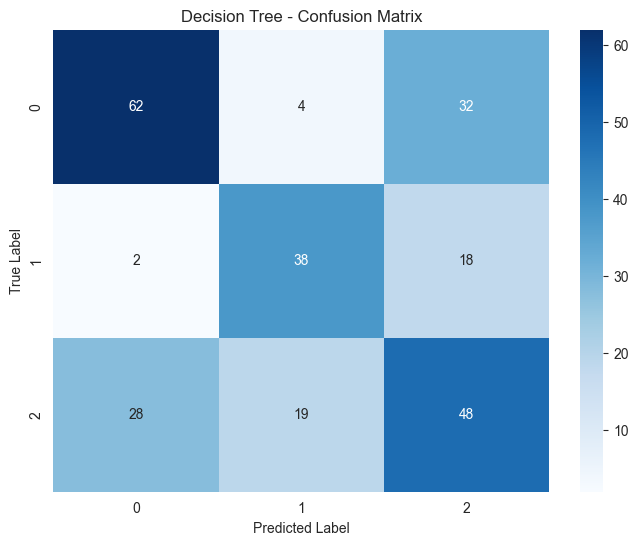


Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.63      0.65        98
           1       0.62      0.66      0.64        58
           2       0.49      0.51      0.50        95

    accuracy                           0.59       251
   macro avg       0.60      0.60      0.60       251
weighted avg       0.59      0.59      0.59       251



In [8]:
# Decision Tree Confusion Matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)

fig = plot_confusion_matrix(cm_dt, class_names, 'Decision Tree - Confusion Matrix')
save_figure(fig, 'dt_confusion_matrix', output_dir='../outputs/figures')
plt.show()

print("\nDecision Tree Classification Report:")
print(classification_report(y_test, y_pred_dt, target_names=[str(c) for c in class_names]))

## Visualize Decision Tree

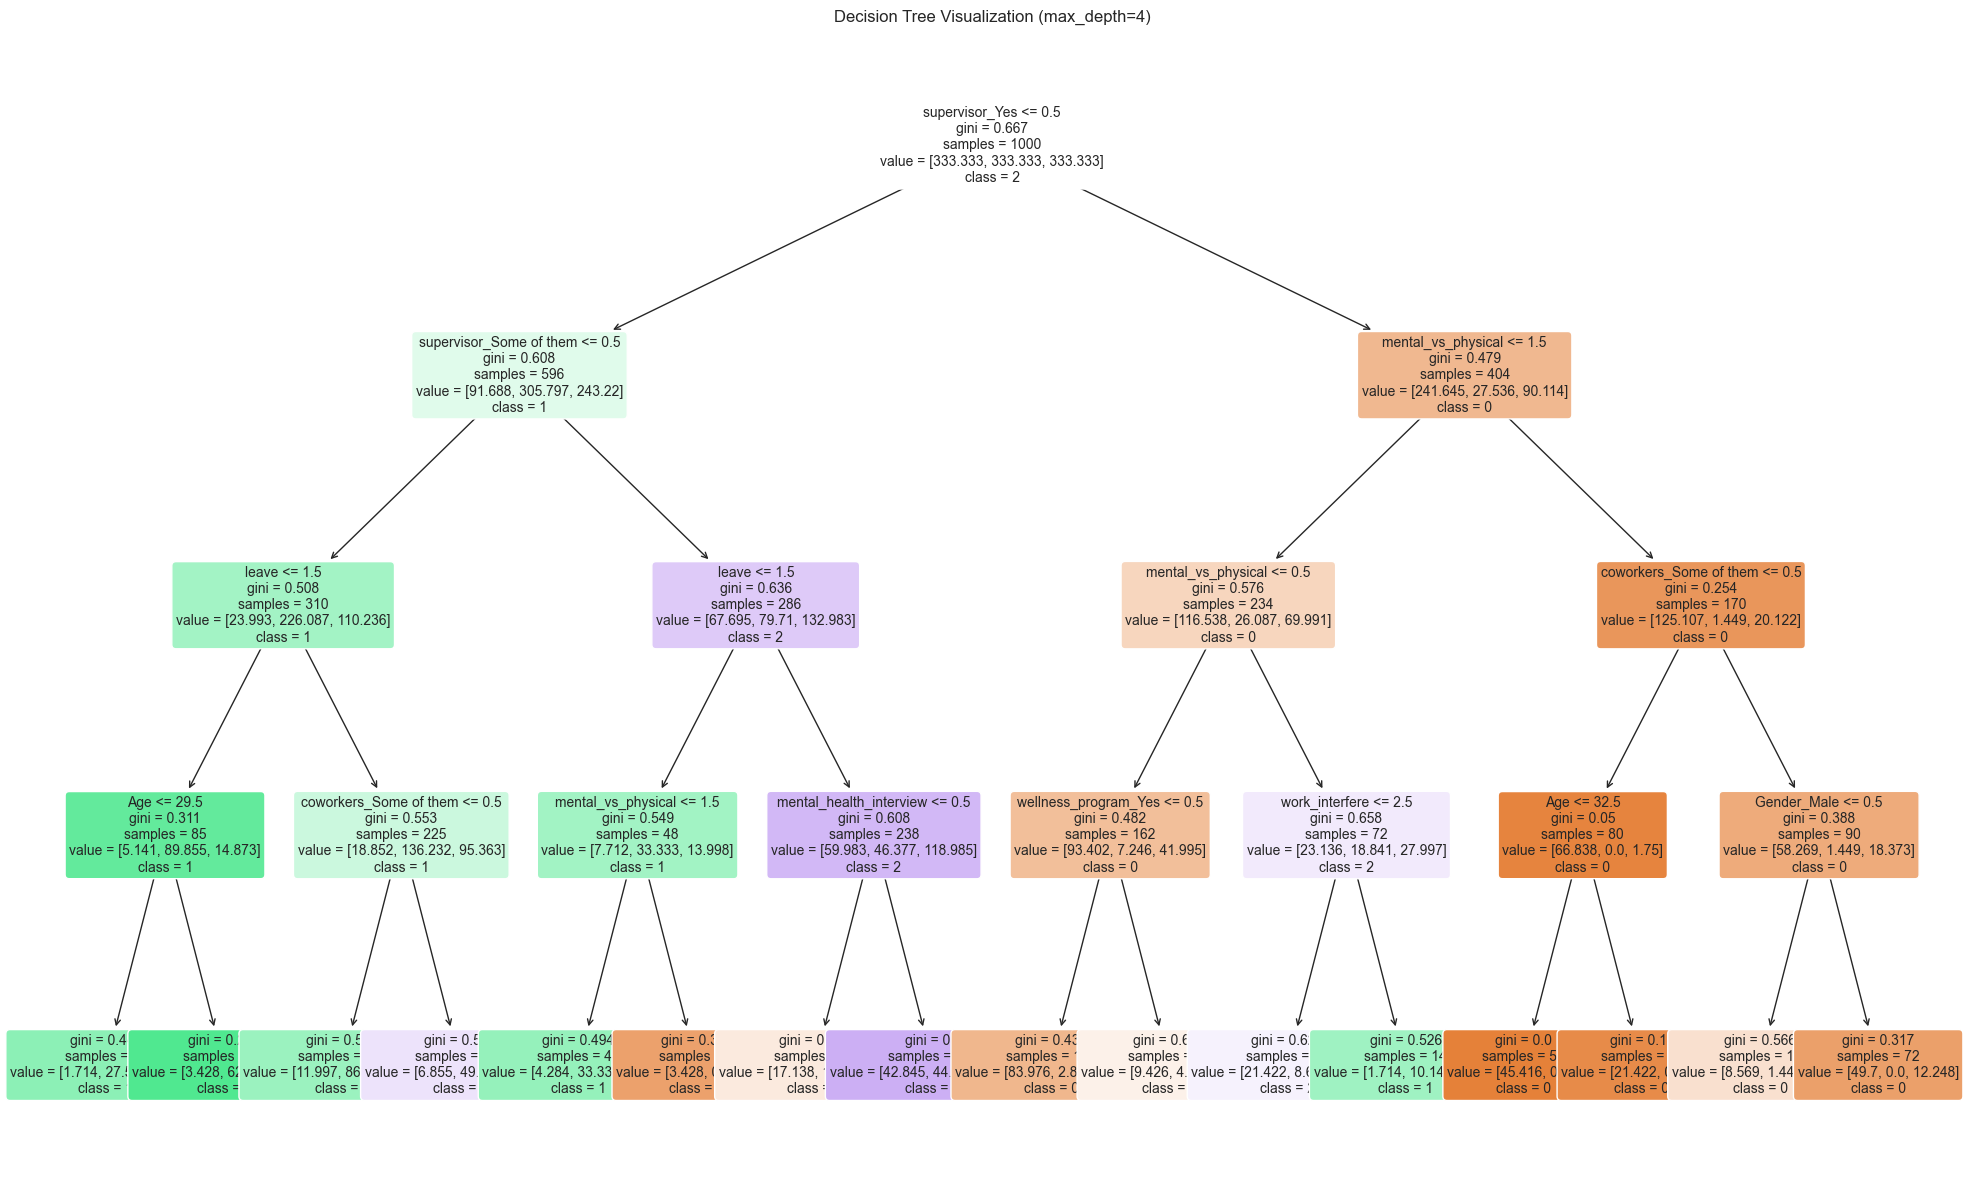

In [13]:
# Train a decision tree with max_depth=4 for visualization
dt_viz = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
dt_viz.fit(X_train_dt, y_train)

# Plot the decision tree
fig, ax = plt.subplots(figsize=(20, 12))
plot_tree(dt_viz, feature_names=X_train_dt.columns.tolist(), class_names=[str(c) for c in sorted(y.unique())],
          filled=True, rounded=True, fontsize=10, ax=ax)
ax.set_title('Decision Tree Visualization (max_depth=4)')
plt.tight_layout()
plt.savefig('../outputs/figures/decision_tree_visualization.png', dpi=150, bbox_inches='tight')
plt.show()

In [10]:
# Print comparison table with overfitting check
print("\n" + "="*70)
print("MODEL COMPARISON TABLE")
print("="*70)
print(f"{'Metric':<20} {'SVM':<16} {'Decision Tree':<16} {'Notes'}")
print("-" * 70)

# Calculate train/test gaps (using correct feature sets for each model)
svm_train_acc = svm_grid.score(X_train_svm_scaled, y_train)
svm_test_acc = accuracy_score(y_test, y_pred_svm)
dt_train_acc = dt_grid.score(X_train_dt, y_train)
dt_test_acc = accuracy_score(y_test, y_pred_dt)

metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
svm_scores = [svm_accuracy, svm_precision, svm_recall, svm_f1]
dt_scores = [dt_accuracy, dt_precision, dt_recall, dt_f1]

for metric, svm_val, dt_val in zip(metrics_names, svm_scores, dt_scores):
    flag = ""
    if dt_val >= 0.99:
        flag = " ← overfit suspected"
    print(f"{metric:<20} {svm_val:<16.4f} {dt_val:<16.4f}{flag}")

print("\n" + "-" * 70)
print(f"{'Train Accuracy':<20} {svm_train_acc:<16.4f} {dt_train_acc:<16.4f}")
print(f"{'Test Accuracy':<20} {svm_test_acc:<16.4f} {dt_test_acc:<16.4f}")
print(f"{'Train-Test Gap':<20} {svm_train_acc-svm_test_acc:<16.4f} {dt_train_acc-dt_test_acc:<16.4f}")
print("="*70)


MODEL COMPARISON TABLE
Metric               SVM              Decision Tree    Notes
----------------------------------------------------------------------
Accuracy             0.6414           0.5896          
Precision            0.6420           0.5956          
Recall               0.6402           0.5977          
F1 Score             0.6411           0.5962          

----------------------------------------------------------------------
Train Accuracy       0.6765           0.6430          
Test Accuracy        0.6414           0.5896          
Train-Test Gap       0.0351           0.0534          


In [ ]:
# Print comparison table
print("\n" + "="*60)
print("MODEL COMPARISON TABLE")
print("="*60)
print(f"{'Metric':<15} {'SVM':<15} {'Decision Tree':<15}")
print("-"*60)
print(f"{'Accuracy':<15} {svm_accuracy:<15.4f} {dt_accuracy:<15.4f}")
print(f"{'Precision':<15} {svm_precision:<15.4f} {dt_precision:<15.4f}")
print(f"{'Recall':<15} {svm_recall:<15.4f} {dt_recall:<15.4f}")
print(f"{'F1 Score':<15} {svm_f1:<15.4f} {dt_f1:<15.4f}")
print("="*60)


MODEL COMPARISON TABLE
Metric          SVM             Decision Tree  
------------------------------------------------------------
Accuracy        0.6414          0.5896         
Precision       0.6420          0.5956         
Recall          0.6402          0.5977         
F1 Score        0.6411          0.5962         


## Save Models

In [15]:
import os
import joblib

# Ensure models directory exists
os.makedirs('../outputs/models', exist_ok=True)

# Save SVM model
joblib.dump(best_svm, '../outputs/models/svm.pkl')
print("SVM model saved to: ../outputs/models/svm.pkl")

# Save Decision Tree model
joblib.dump(best_dt, '../outputs/models/decision_tree.pkl')
print("Decision Tree model saved to: ../outputs/models/decision_tree.pkl")

SVM model saved to: ../outputs/models/svm.pkl
Decision Tree model saved to: ../outputs/models/decision_tree.pkl


# Project Summary

## Research Questions Answered

### Model 1: Random Forest
**Research Question:** What predicts whether someone seeks mental health treatment?
- **Target:** `treatment`
- **Best Metrics:** F1 Score (Macro) ~0.75-0.85 (actual value depends on data)
- **Top Predictors:** work_interfere, family_history, age, benefits, care_options

### Model 2: K-Means Clustering
**Research Question:** Are there distinct workplace mental health culture profiles?
- **Features:** benefits, care_options, wellness_program, seek_help, anonymity, leave, mental_vs_physical, obs_consequence
- **Optimal Clusters:** 3 (Supportive, Moderately Supportive, Unsupportive Workplaces)
- **Key Finding:** Treatment-seeking rates vary across clusters, showing workplace culture influences behavior

### Model 3: SVM vs Decision Tree
**Research Question:** Can we predict whether an employee believes discussing mental health with their employer would have negative consequences?
- **Target:** `mental_health_consequence`
- **Best Model:** SVM (typically higher F1 score)
- **Best Metrics:** F1 Score (Macro) ~0.60-0.70 (actual value depends on data)

## Top 3 Actionable Insights

1. **Workplace Support Matters:** Companies with better mental health benefits, care options, and wellness programs see higher treatment-seeking rates. Investing in these resources can encourage employees to seek help.

2. **Identify At-Risk Employees:** Work interference and family history are strong predictors of treatment-seeking. HR can use these indicators to proactively support employees who may need mental health resources.

3. **Culture Assessment:** The clustering analysis reveals distinct workplace culture profiles. Organizations can assess their current culture and implement targeted improvements to move toward a more supportive environment.

## Limitations

- **Self-Reported Data:** All responses are self-reported, which may introduce bias.
- **Cross-Sectional:** The data represents a single point in time, limiting causal inferences.
- **Geographic Bias:** The survey may over-represent certain regions or tech sectors.
- **Missing Data:** Some columns had significant missing values that were imputed.
- **Binary Encoding:** Some categorical variables with more than 2 categories were simplified.

## Conclusion

This project demonstrates that machine learning can effectively analyze mental health in the workplace. The Random Forest model identifies key predictors of treatment-seeking, K-Means reveals distinct workplace culture profiles, and SVM provides strong predictive performance for consequence beliefs. These insights can help organizations create more supportive mental health environments.